In [63]:
# Step 1: Data Cleaning

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '../data/telecom_data.csv'  # Replace with the correct path
df = pd.read_csv(file_path)

# Display initial dataset info
print("Initial Dataset Information:")
print(df.info())

# Drop irrelevant columns (IDs, timestamps, or string-based identifiers)
columns_to_drop = ['Bearer Id', 'IMSI', 'IMEI', 'Start', 'End', 'Start ms', 'End ms']
df_cleaned = df.drop(columns=columns_to_drop, errors='ignore')

# Select only numeric columns
numeric_columns = df_cleaned.select_dtypes(include=['number']).columns
df_cleaned = df_cleaned[numeric_columns]

# Handle missing values (replace with column means)
df_cleaned = df_cleaned.fillna(df_cleaned.mean())

# Final cleaned dataset info
print("\nCleaned Dataset Information:")
print(df_cleaned.info())

# Display first few rows of the cleaned dataset
print("\nFirst 5 Rows of Cleaned Data:")
print(df_cleaned.head())


Initial Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150001 entries, 0 to 150000
Data columns (total 55 columns):
 #   Column                                    Non-Null Count   Dtype  
---  ------                                    --------------   -----  
 0   Bearer Id                                 149010 non-null  float64
 1   Start                                     150000 non-null  object 
 2   Start ms                                  150000 non-null  float64
 3   End                                       150000 non-null  object 
 4   End ms                                    150000 non-null  float64
 5   Dur. (ms)                                 150000 non-null  float64
 6   IMSI                                      149431 non-null  float64
 7   MSISDN/Number                             148935 non-null  float64
 8   IMEI                                      149429 non-null  float64
 9   Last Location Name                        148848 non-null  obje


Top 10 Handsets Used by Customers:
Handset Type
Huawei B528S-23A                19752
Apple iPhone 6S (A1688)          9419
Apple iPhone 6 (A1586)           9023
undefined                        8987
Apple iPhone 7 (A1778)           6326
Apple iPhone Se (A1723)          5187
Apple iPhone 8 (A1905)           4993
Apple iPhone Xr (A2105)          4568
Samsung Galaxy S8 (Sm-G950F)     4520
Apple iPhone X (A1901)           3813
Name: count, dtype: int64


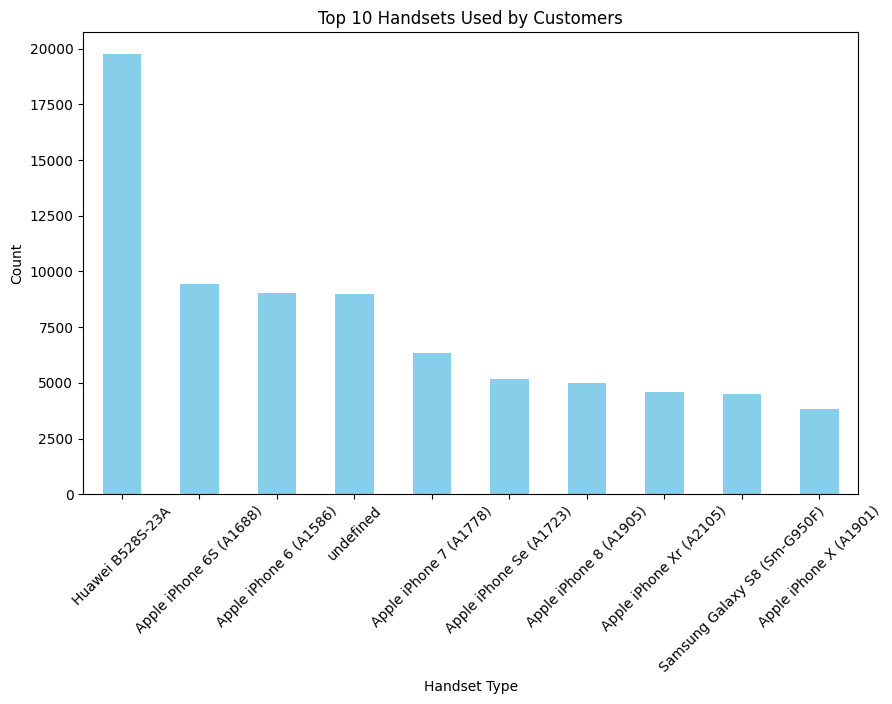

In [64]:
# Step 2: Identify Top 10 Handsets Used by Customers

# Count occurrences of each handset type and get the top 10
top_10_handsets = df['Handset Type'].value_counts().head(10)

# Print the result
print("\nTop 10 Handsets Used by Customers:")
print(top_10_handsets)

# Plot the top 10 handsets
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
top_10_handsets.plot(kind='bar', color='skyblue')
plt.title("Top 10 Handsets Used by Customers")
plt.xlabel("Handset Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()



Top 3 Handset Manufacturers:
Handset Manufacturer
Apple      59565
Samsung    40839
Huawei     34423
Name: count, dtype: int64


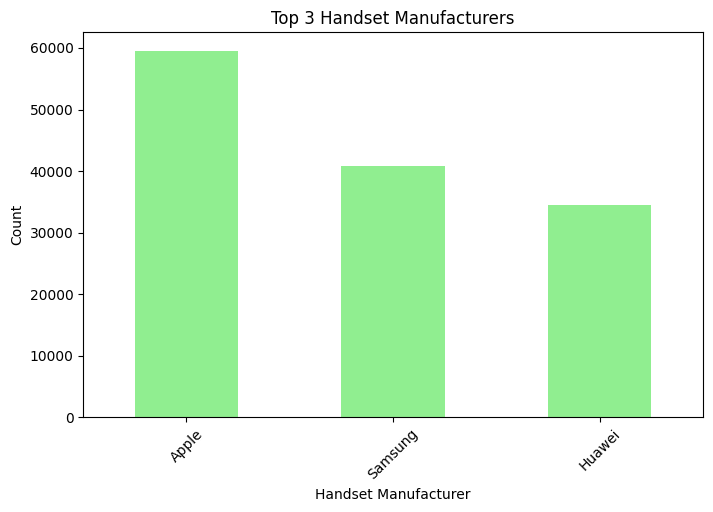

In [65]:
# Step 3: Identify Top 3 Handset Manufacturers

# Count occurrences of each handset manufacturer and get the top 3
top_3_manufacturers = df['Handset Manufacturer'].value_counts().head(3)

# Print the result
print("\nTop 3 Handset Manufacturers:")
print(top_3_manufacturers)

# Plot the top 3 handset manufacturers
plt.figure(figsize=(8, 5))
top_3_manufacturers.plot(kind='bar', color='lightgreen')
plt.title("Top 3 Handset Manufacturers")
plt.xlabel("Handset Manufacturer")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()



Top 5 Handsets per Top 3 Manufacturers:

Top 5 Handsets for Manufacturer: Apple
Handset Type
Apple iPhone 6S (A1688)    9419
Apple iPhone 6 (A1586)     9023
Apple iPhone 7 (A1778)     6326
Apple iPhone Se (A1723)    5187
Apple iPhone 8 (A1905)     4993
Name: count, dtype: int64


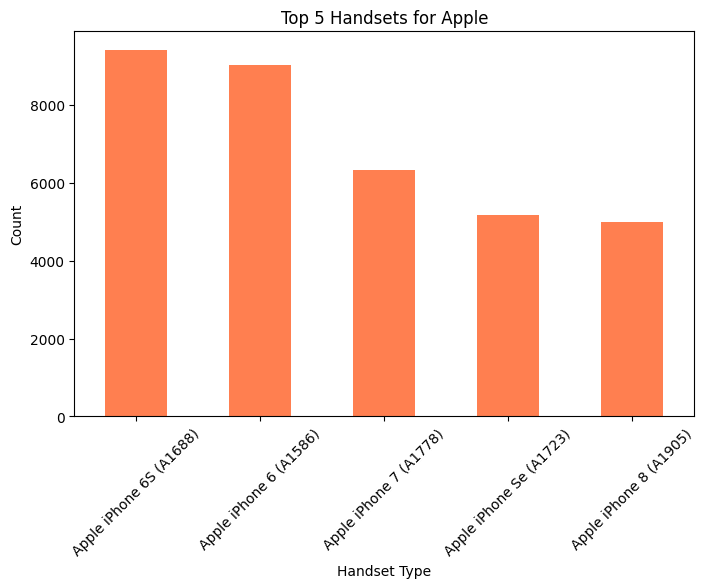


Top 5 Handsets for Manufacturer: Samsung
Handset Type
Samsung Galaxy S8 (Sm-G950F)    4520
Samsung Galaxy A5 Sm-A520F      3724
Samsung Galaxy J5 (Sm-J530)     3696
Samsung Galaxy J3 (Sm-J330)     3484
Samsung Galaxy S7 (Sm-G930X)    3199
Name: count, dtype: int64


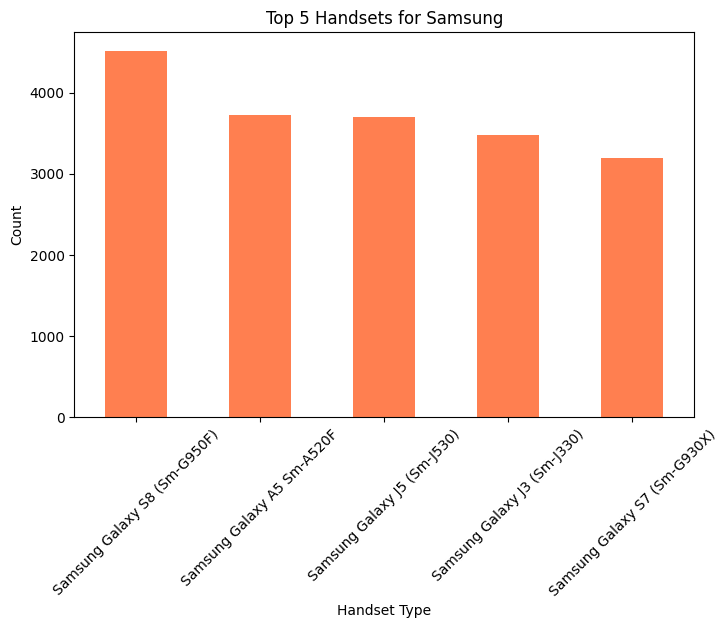


Top 5 Handsets for Manufacturer: Huawei
Handset Type
Huawei B528S-23A                  19752
Huawei E5180                       2079
Huawei P20 Lite Huawei Nova 3E     2021
Huawei P20                         1480
Huawei Y6 2018                      997
Name: count, dtype: int64


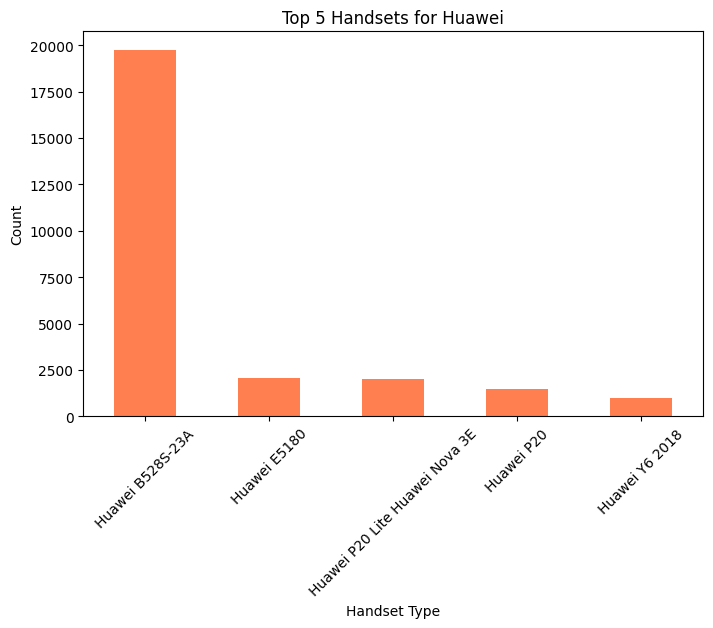

In [66]:
# Step 4: Top 5 Handsets per Top 3 Manufacturers

# Loop through the top 3 manufacturers and get the top 5 handsets for each
print("\nTop 5 Handsets per Top 3 Manufacturers:")
for manufacturer in top_3_manufacturers.index:
    top_5_handsets = df[df['Handset Manufacturer'] == manufacturer]['Handset Type'].value_counts().head(5)
    print(f"\nTop 5 Handsets for Manufacturer: {manufacturer}")
    print(top_5_handsets)

    # Plot the top 5 handsets for each manufacturer
    plt.figure(figsize=(8, 5))
    top_5_handsets.plot(kind='bar', color='coral')
    plt.title(f"Top 5 Handsets for {manufacturer}")
    plt.xlabel("Handset Type")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()


In [67]:
# Step 5: Aggregate User Behavior Analysis

# Group by 'MSISDN/Number' and aggregate data
user_behavior = df.groupby('MSISDN/Number').agg({
    'Dur. (ms)': 'sum',                       # Total session duration
    'Total UL (Bytes)': 'sum',                # Total upload data
    'Total DL (Bytes)': 'sum',                # Total download data
    'Social Media DL (Bytes)': 'sum',
    'Google DL (Bytes)': 'sum',
    'Email DL (Bytes)': 'sum',
    'Youtube DL (Bytes)': 'sum',
    'Netflix DL (Bytes)': 'sum',
    'Gaming DL (Bytes)': 'sum',
    'Other DL (Bytes)': 'sum'
}).reset_index()

# Calculate total data volume (UL + DL)
user_behavior['Total Data Volume (Bytes)'] = user_behavior['Total UL (Bytes)'] + user_behavior['Total DL (Bytes)']

# Display the result
print("\nAggregated User Behavior Data:")
print(user_behavior.head())



Aggregated User Behavior Data:
   MSISDN/Number  Dur. (ms)  Total UL (Bytes)  Total DL (Bytes)  \
0   3.360100e+10   116720.0        36053108.0      8.426375e+08   
1   3.360100e+10   181230.0        36104459.0      1.207552e+08   
2   3.360100e+10   134969.0        39306820.0      5.566597e+08   
3   3.360101e+10    49878.0        20327526.0      4.019932e+08   
4   3.360101e+10    37104.0        94280527.0      1.363130e+09   

   Social Media DL (Bytes)  Google DL (Bytes)  Email DL (Bytes)  \
0                2206504.0          3337123.0          837400.0   
1                2598548.0          4197697.0         2828821.0   
2                3148004.0          3343483.0         2436500.0   
3                 251469.0          5937765.0         2178618.0   
4                2861230.0         13728668.0         2247808.0   

   Youtube DL (Bytes)  Netflix DL (Bytes)  Gaming DL (Bytes)  \
0          14900201.0          10265105.0       8.110911e+08   
1           5324251.0            7

In [68]:
# Step 6.1: Describe Variables
print("\nDataset Information for Aggregated User Behavior Data:")
print(user_behavior.info())
print("\nStatistical Summary of User Behavior Data:")
print(user_behavior.describe())



Dataset Information for Aggregated User Behavior Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106856 entries, 0 to 106855
Data columns (total 12 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   MSISDN/Number              106856 non-null  float64
 1   Dur. (ms)                  106856 non-null  float64
 2   Total UL (Bytes)           106856 non-null  float64
 3   Total DL (Bytes)           106856 non-null  float64
 4   Social Media DL (Bytes)    106856 non-null  float64
 5   Google DL (Bytes)          106856 non-null  float64
 6   Email DL (Bytes)           106856 non-null  float64
 7   Youtube DL (Bytes)         106856 non-null  float64
 8   Netflix DL (Bytes)         106856 non-null  float64
 9   Gaming DL (Bytes)          106856 non-null  float64
 10  Other DL (Bytes)           106856 non-null  float64
 11  Total Data Volume (Bytes)  106856 non-null  float64
dtypes: float64(12)
memory usage: 9


Total Data Volume per Decile Class:
Decile
0    1.154869e+13
1    1.257064e+13
2    1.156998e+13
3    1.397471e+13
4    2.416942e+13
Name: Total Data Volume (Bytes), dtype: float64


C:\Users\robiti\AppData\Local\Temp\ipykernel_15676\2228832763.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=decile_data.index, y=decile_data.values, palette="Blues_d")


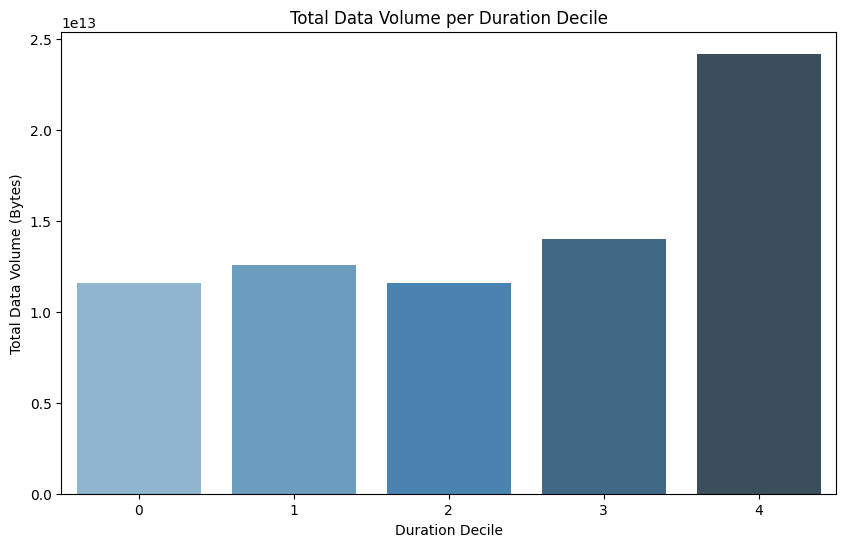

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 6.2: Segment Users into Decile Classes Based on Total Duration

# Create decile classes using 'Dur. (ms)' to split users into 5 groups
user_behavior['Decile'] = pd.qcut(user_behavior['Dur. (ms)'], 5, labels=False)

# Compute the total data volume (DL + UL) per decile
decile_data = user_behavior.groupby('Decile')['Total Data Volume (Bytes)'].sum()

# Display decile data
print("\nTotal Data Volume per Decile Class:")
print(decile_data)

# Visualize the Total Data Volume per Decile
plt.figure(figsize=(10, 6))
sns.barplot(x=decile_data.index, y=decile_data.values, palette="Blues_d")
plt.title("Total Data Volume per Duration Decile")
plt.xlabel("Duration Decile")
plt.ylabel("Total Data Volume (Bytes)")
plt.show()

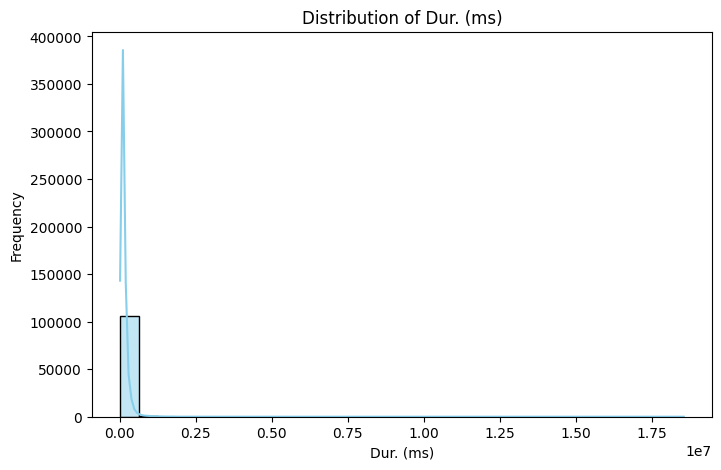

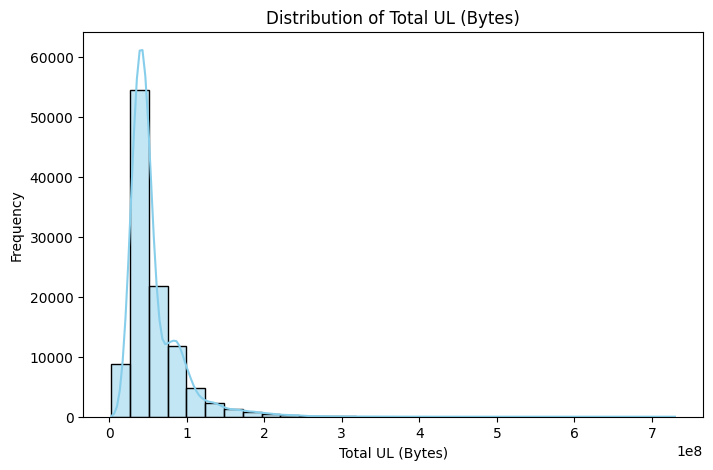

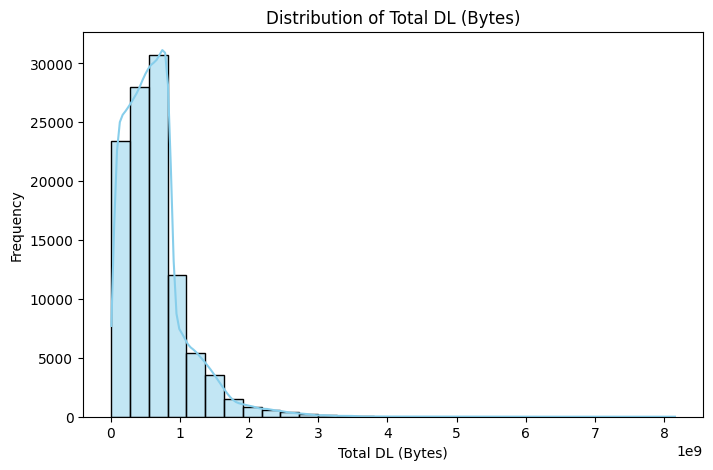

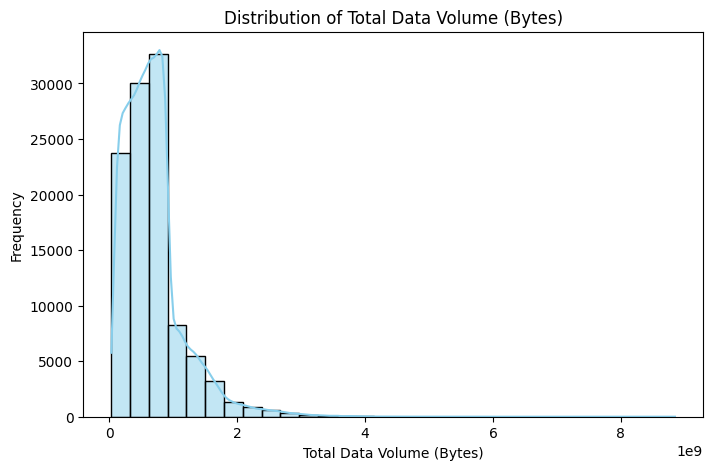

In [70]:
# Step 6.3: Graphical Univariate Analysis - Histograms for Key Variables

key_columns = ['Dur. (ms)', 'Total UL (Bytes)', 'Total DL (Bytes)', 'Total Data Volume (Bytes)']

for col in key_columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(user_behavior[col], bins=30, kde=True, color='skyblue')
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()


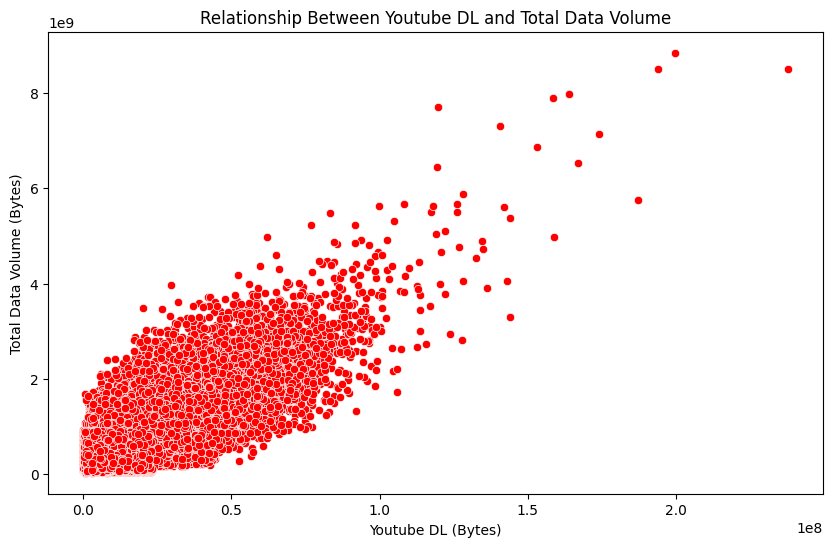

In [71]:
# Step 6.4: Bivariate Analysis

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Youtube DL (Bytes)', y='Total Data Volume (Bytes)', data=user_behavior, color='red')
plt.title("Relationship Between Youtube DL and Total Data Volume")
plt.xlabel("Youtube DL (Bytes)")
plt.ylabel("Total Data Volume (Bytes)")
plt.show()


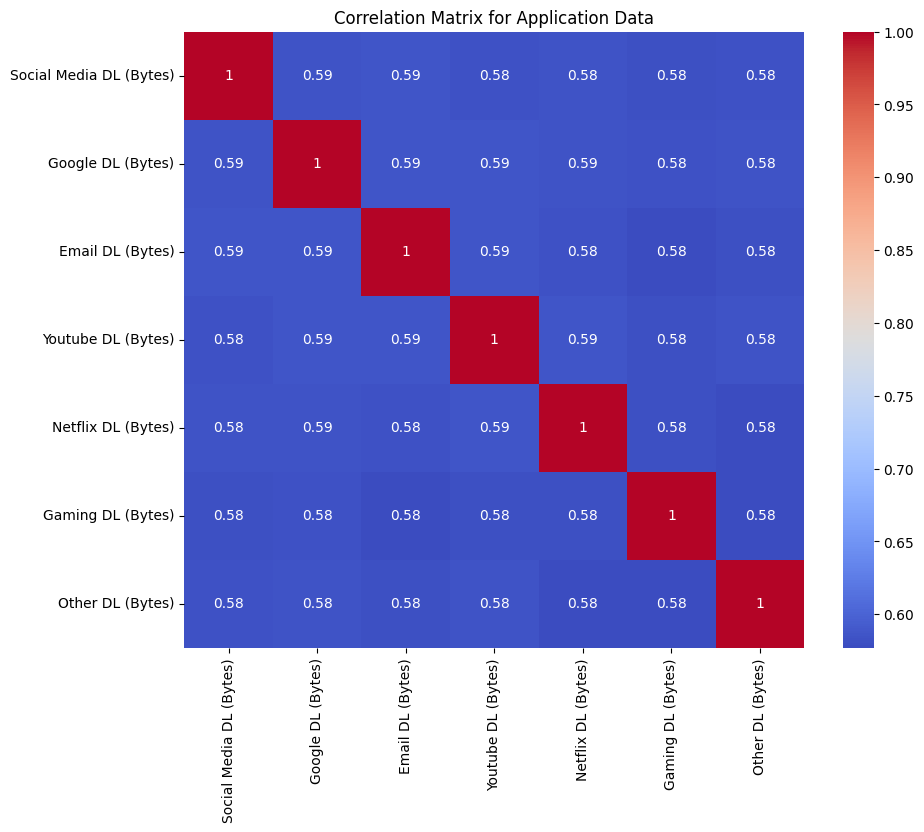

In [72]:
# Step 6.5: Correlation Analysis for Application Data

selected_columns = [
    'Social Media DL (Bytes)', 'Google DL (Bytes)', 'Email DL (Bytes)',
    'Youtube DL (Bytes)', 'Netflix DL (Bytes)', 'Gaming DL (Bytes)', 'Other DL (Bytes)'
]

# Calculate correlation matrix
correlation_matrix = user_behavior[selected_columns].corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix for Application Data")
plt.show()


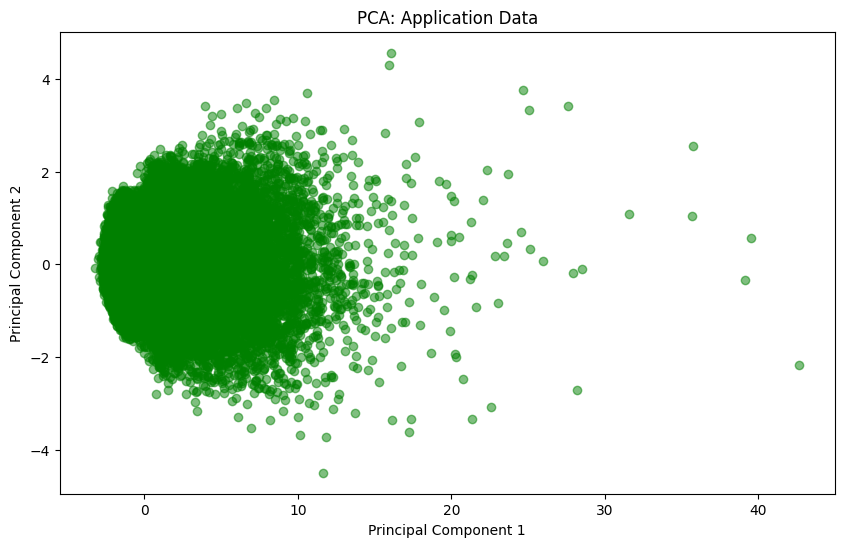


Explained Variance Ratio by PCA Components:
[0.64259153 0.0606768 ]


In [73]:
# Step 6.6: Dimensionality Reduction Using PCA

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Scale the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(user_behavior[selected_columns])

# Perform PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

# Plot PCA results
plt.figure(figsize=(10, 6))
plt.scatter(pca_result[:, 0], pca_result[:, 1], alpha=0.5, color='green')
plt.title("PCA: Application Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Print explained variance ratio
print("\nExplained Variance Ratio by PCA Components:")
print(pca.explained_variance_ratio_)



Explained Variance Ratio by Components:
[0.64259153 0.0606768 ]


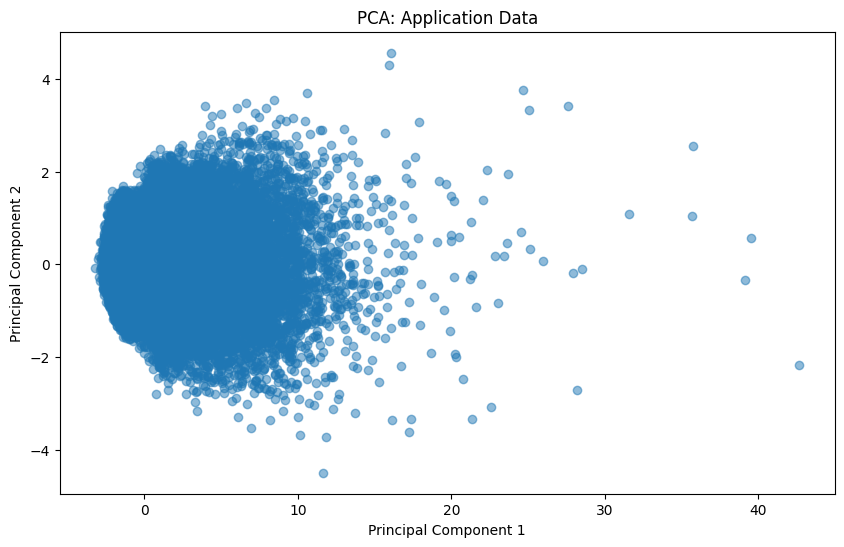

In [74]:
# Step 7: Principal Component Analysis (PCA)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(user_behavior[selected_columns])

# Apply PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

print("\nExplained Variance Ratio by Components:")
print(pca.explained_variance_ratio_)

# Plot PCA results
plt.figure(figsize=(10, 6))
plt.scatter(pca_result[:, 0], pca_result[:, 1], alpha=0.5)
plt.title("PCA: Application Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()
